# 03 · E0 (baseline) y E1 (extracción de características)
**Entrega 1 · días 3–7.** Necesita GPU: menú *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.

Antes de ejecutar: el protocolo (`docs/02_protocolo.md`) y las hipótesis de E0 y E1 (`docs/03_hipotesis.md`) deben estar escritos.

In [2]:
# PREPARACIÓN (igual en todos los notebooks): conecta Drive, entra a la carpeta del proyecto y deja listos los datos.
from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/yuca-comparacion'   # carpeta del proyecto dentro de su Google Drive

import os, sys
os.chdir(PROYECTO)
sys.path.insert(0, PROYECTO)

from src.datos import descargar_dataset
# El .zip se guarda una sola vez en Drive; las fotos se descomprimen en el disco de Colab (más rápido).
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ
print('Proyecto:', os.getcwd())
print('Datos   :', RAIZ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[1/2] Ya existe el archivo /content/drive/MyDrive/yuca-comparacion/data/cassavaleafdata.zip; no se descarga de nuevo.
[2/2] Descomprimiendo...
[ok] Dataset listo en: /content/datos/cassavaleafdata
Proyecto: /content/drive/MyDrive/yuca-comparacion
Datos   : /content/datos/cassavaleafdata


In [3]:
import torch
print('GPU disponible:', torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'SIN GPU: menú Entorno de ejecución > Cambiar tipo de entorno > T4 GPU')

GPU disponible: True
Tesla T4


In [4]:
# Configuración con la que se va a ejecutar (viene de configs/config.yaml)
import yaml, json
from src.comun import cargar_config
print(yaml.safe_dump(cargar_config(), allow_unicode=True, sort_keys=False))

datos:
  url: https://storage.googleapis.com/emcassavadata/cassavaleafdata.zip
  raiz: /content/datos/cassavaleafdata
  clases:
  - cbb
  - cbsd
  - cgm
  - cmd
  - healthy
protocolo:
  semilla: 42
  tamano_imagen: 224
  tamano_lote: 32
  metrica_principal: macro_f1
  pesos_por_clase: true
  trabajadores: 2
e0:
  tipo: cnn_pequena
  tamano_imagen: 64
  epocas: 10
  tasa_aprendizaje: 0.001
extraccion:
  backbone_a: resnet18
  backbone_b: mobilenet_v2
  epocas: 10
  tasa_aprendizaje: 0.001
ajuste_fino:
  epocas: 5
  tasa_aprendizaje: 0.0001
adicional:
  factores_brillo:
  - 0.5
  - 0.75
  - 1.0
  - 1.25
  - 1.5



## E0 · Baseline
Una red pequeña entrenada desde cero, sin conocimiento previo. Responde: *¿qué se consigue sin una arquitectura sofisticada?*

In [5]:
from src.entrenar import ejecutar
m0 = ejecutar('E0')

[2026-11-16 04:10:46] === E0: Baseline sin preentrenamiento ===
[2026-11-16 04:10:46] Dispositivo: Tesla T4 | semilla: 42
[2026-11-16 04:10:47] Imágenes: train=5600 val=1877 test=1885
[2026-11-16 04:10:47] Parámetros: 24,133 totales, 24,133 entrenables, 0.1 MB
[2026-11-16 04:11:24] Época  1/10 | train pérdida 1.4868 F1 0.2957 | val pérdida 1.4110 F1 0.2843 acc 0.3308  <- mejor hasta ahora (guardado)
[2026-11-16 04:11:58] Época  2/10 | train pérdida 1.3970 F1 0.3433 | val pérdida 1.3409 F1 0.3470 acc 0.4582  <- mejor hasta ahora (guardado)
[2026-11-16 04:12:33] Época  3/10 | train pérdida 1.3502 F1 0.3662 | val pérdida 1.4140 F1 0.3092 acc 0.3351
[2026-11-16 04:13:09] Época  4/10 | train pérdida 1.3233 F1 0.3674 | val pérdida 1.1532 F1 0.3677 acc 0.5402  <- mejor hasta ahora (guardado)
[2026-11-16 04:13:43] Época  5/10 | train pérdida 1.2851 F1 0.3997 | val pérdida 1.3568 F1 0.3607 acc 0.4198
[2026-11-16 04:14:17] Época  6/10 | train pérdida 1.2716 F1 0.4133 | val pérdida 1.2384 F1 0.40

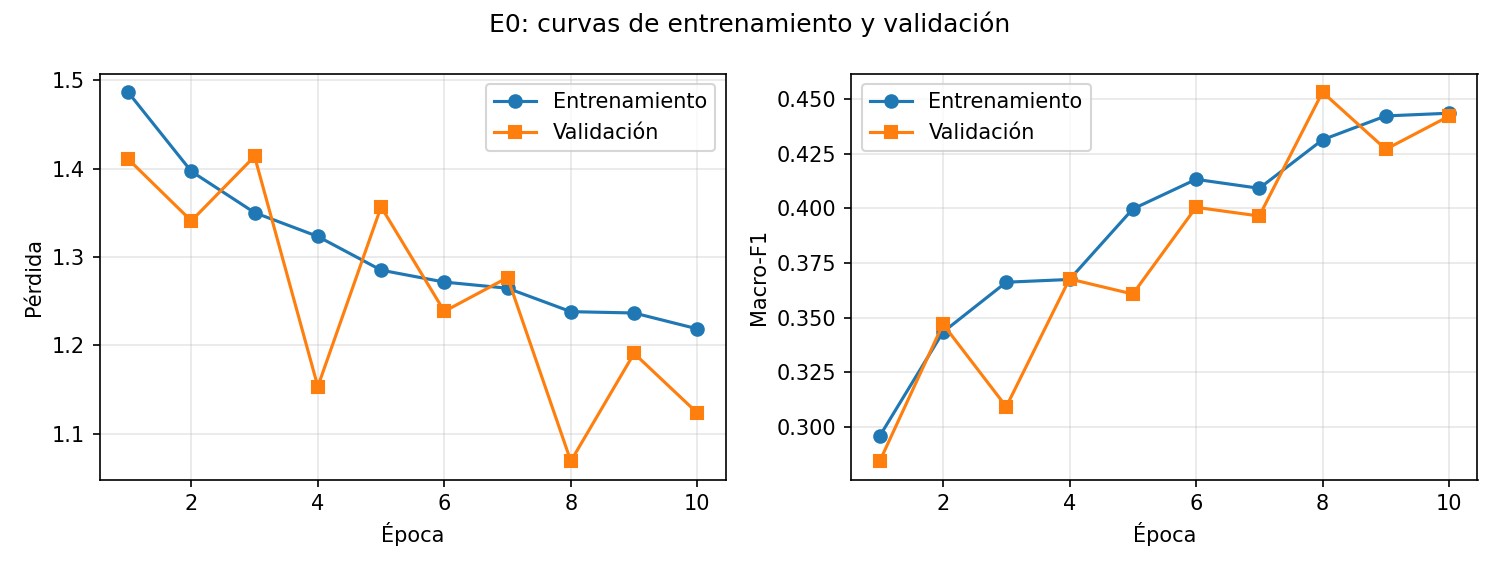

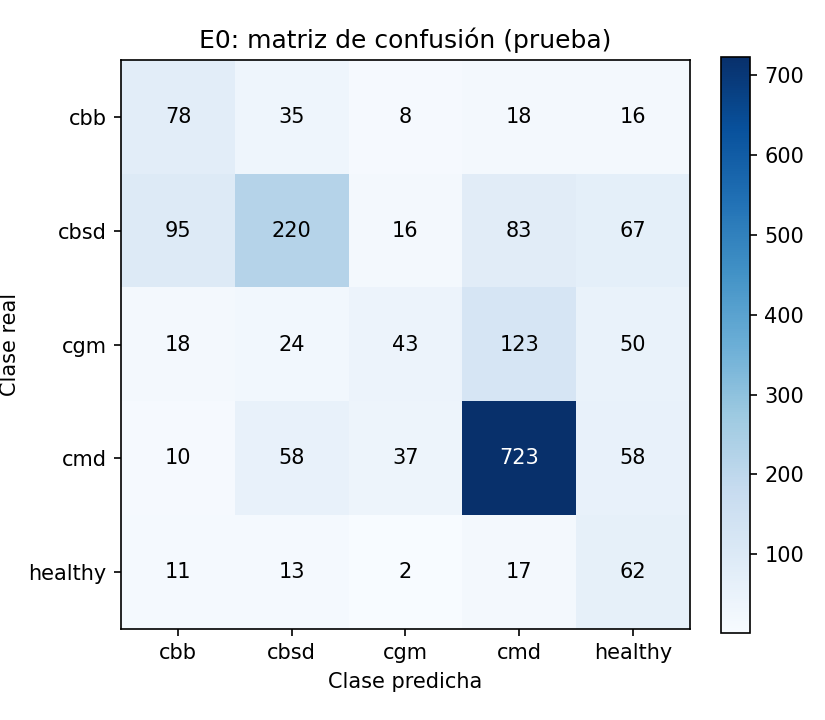

,precision,recall,f1,imagenes
cbb,0.367925,0.503226,0.425068,155.0
cbsd,0.628571,0.457380,0.529483,481.0
cgm,0.405660,0.166667,0.236264,258.0
cmd,0.750000,0.816027,0.781622,886.0
healthy,0.245059,0.590476,0.346369,105.0


In [6]:
from IPython.display import Image as Mostrar, display
import pandas as pd
display(Mostrar('resultados/E0/curvas.png'))
display(Mostrar('resultados/E0/matriz_confusion.png'))
pd.DataFrame(m0['por_clase']).T

## E1 · Extracción de características con el Backbone A
El backbone preentrenado queda **congelado** (no cambia); solo aprende la cabeza clasificadora de 5 salidas.
Responde: *¿qué aporta el aprendizaje por transferencia?*

Para una ejecución parcial de prueba (pocas épocas) usar `ejecutar('E1', epocas=2)`: se guarda aparte como `PRUEBA_E1`.

In [7]:
m1 = ejecutar('E1')

[2026-11-16 04:16:44] === E1: Backbone A congelado, solo cabeza ===
[2026-11-16 04:16:44] Dispositivo: Tesla T4 | semilla: 42
[2026-11-16 04:16:44] Imágenes: train=5600 val=1877 test=1885
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]

[2026-11-16 04:16:45] Parámetros: 11,179,077 totales, 2,565 entrenables, 44.75 MB


[2026-11-16 04:17:41] Época  1/10 | train pérdida 1.2894 F1 0.4110 | val pérdida 1.0318 F1 0.5263 acc 0.6100  <- mejor hasta ahora (guardado)
[2026-11-16 04:18:34] Época  2/10 | train pérdida 0.9971 F1 0.5666 | val pérdida 0.8874 F1 0.5708 acc 0.6713  <- mejor hasta ahora (guardado)
[2026-11-16 04:19:29] Época  3/10 | train pérdida 0.9279 F1 0.5923 | val pérdida 0.8307 F1 0.6251 acc 0.7017  <- mejor hasta ahora (guardado)
[2026-11-16 04:20:24] Época  4/10 | train pérdida 0.8960 F1 0.5981 | val pérdida 0.8449 F1 0.6185 acc 0.6926
[2026-11-16 04:21:17] Época  5/10 | train pérdida 0.8847 F1 0.6030 | val pérdida 0.7988 F1 0.6464 acc 0.7198  <- mejor hasta ahora (guardado)
[2026-11-16 04:22:12] Época  6/10 | train pérdida 0.8637 F1 0.6128 | val pérdida 0.7650 F1 0.6378 acc 0.7235
[2026-11-16 04:23:05] Época  7/10 | train pérdida 0.8493 F1 0.6098 | val pérdida 0.8011 F1 0.6450 acc 0.7123
[2026-11-16 04:23:59] Época  8/10 | train pérdida 0.8319 F1 0.6173 | val pérdida 0.7387 F1 0.6617 acc 0.7

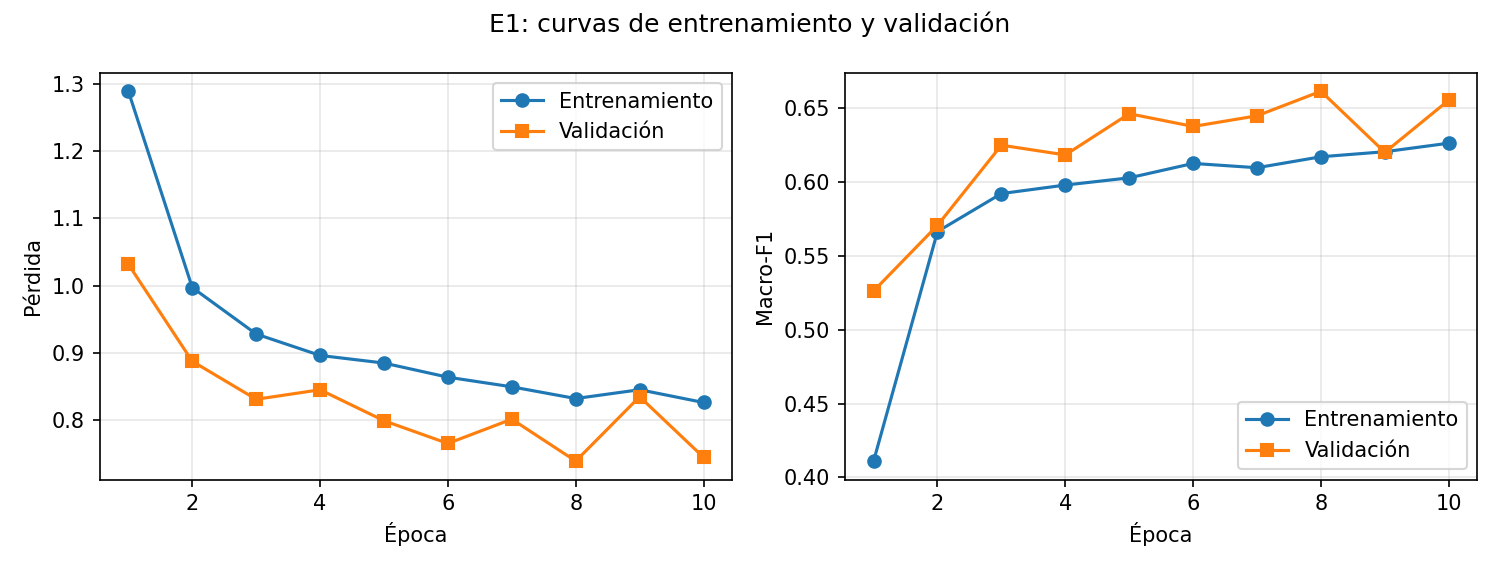

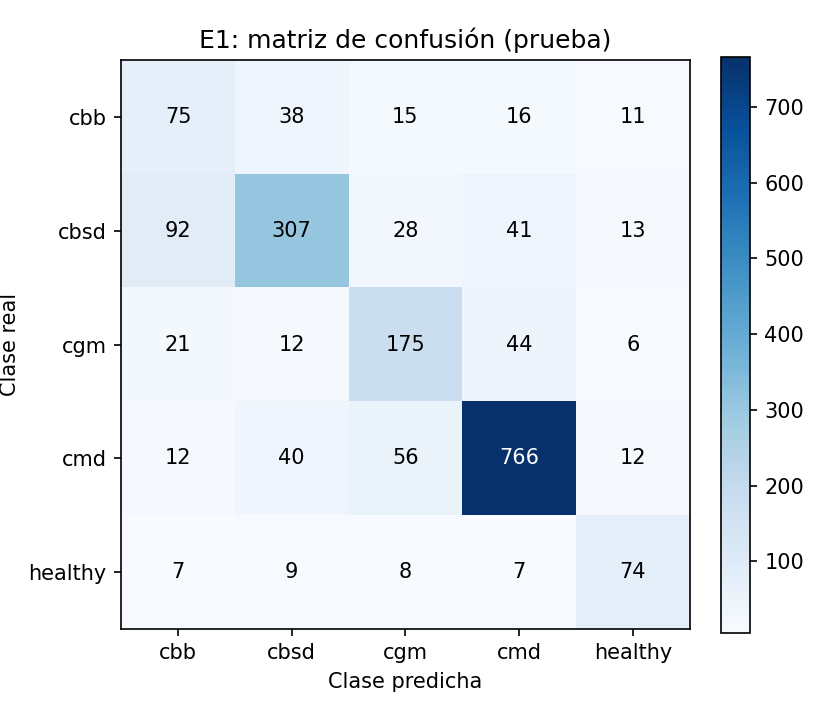

,precision,recall,f1,imagenes
cbb,0.362319,0.483871,0.414365,155.0
cbsd,0.756158,0.638254,0.692221,481.0
cgm,0.620567,0.678295,0.648148,258.0
cmd,0.876430,0.864560,0.870455,886.0
healthy,0.637931,0.704762,0.669683,105.0


In [8]:
display(Mostrar('resultados/E1/curvas.png'))
display(Mostrar('resultados/E1/matriz_confusion.png'))
pd.DataFrame(m1['por_clase']).T

## Métricas iniciales: E0 frente a E1

In [9]:
from src import analisis
analisis.tabla_consolidada(('E0', 'E1')).T

,0,1
Exp.,E0,E1
Modelo,cnn_pequena,resnet18
Accuracy,0.5973,0.7411
Macro-F1,0.4638,0.659
Val macro-F1,0.4532,0.6617
Mejor época,8,8
Entren. (s),347.7,542.7
Entren. acumulado (s),347.7,542.7
Inferencia ms/img (lote 1),0.576,3.717
Inferencia ms/img (en lote),0.033,0.9


## Registro de errores de E1
Los errores en los que el modelo estaba más seguro. Las hipótesis sobre por qué falló las escribe el equipo en la bitácora.

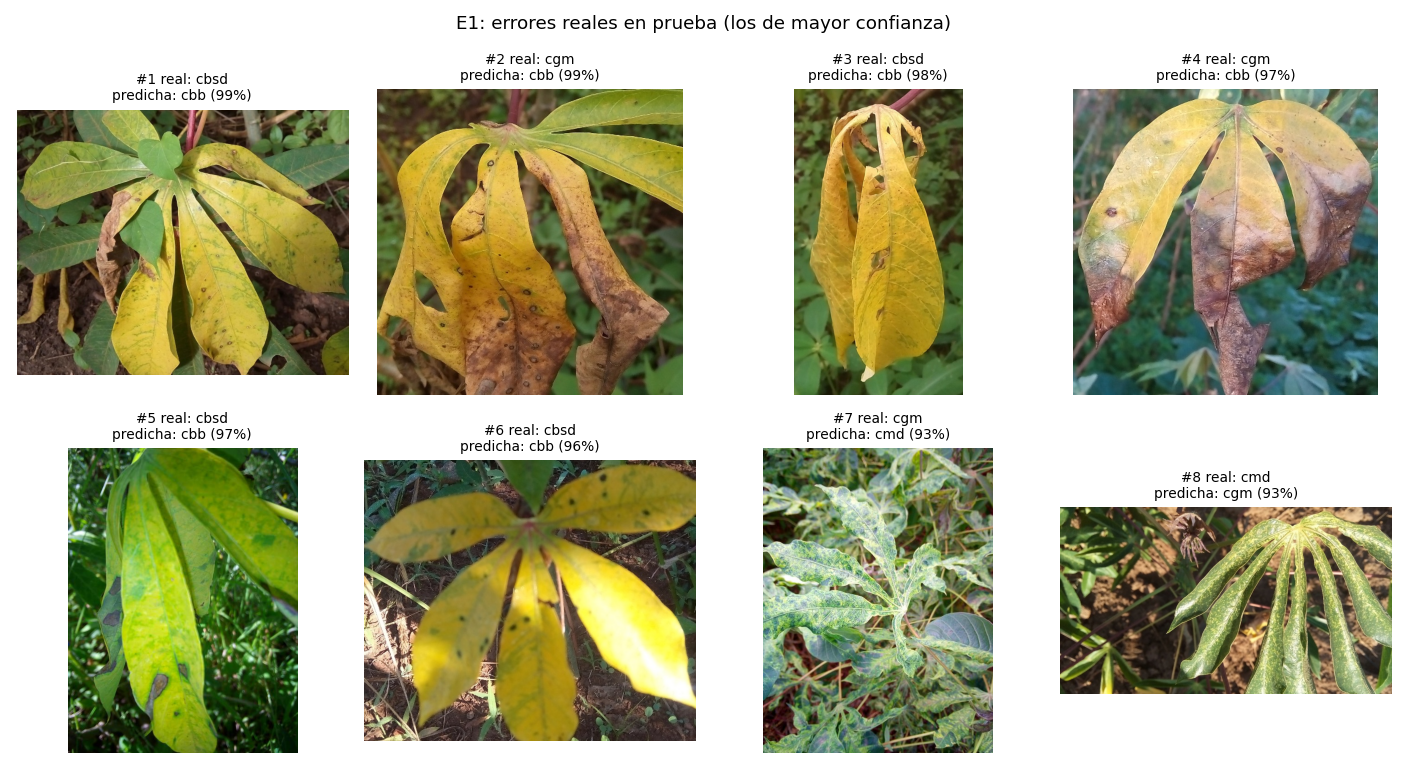

,ruta,real,predicha,confianza
0,test/cbsd/test-cbsd-311.jpg,cbsd,cbb,0.9902
1,test/cgm/test-cgm-136.jpg,cgm,cbb,0.9882
2,test/cbsd/test-cbsd-88.jpg,cbsd,cbb,0.9839
3,test/cgm/test-cgm-102.jpg,cgm,cbb,0.9729
4,test/cbsd/test-cbsd-215.jpg,cbsd,cbb,0.9708
5,test/cbsd/test-cbsd-331.jpg,cbsd,cbb,0.9580
6,test/cgm/test-cgm-87.jpg,cgm,cmd,0.9313
7,test/cmd/test-cmd-294.jpg,cmd,cgm,0.9284


In [10]:
errores = analisis.galeria_errores('E1', n=8)
display(Mostrar('resultados/E1/galeria_errores.png'))
errores[['ruta', 'real', 'predicha', 'confianza']]

In [11]:
analisis.pares_confundidos('E1')   # confusiones más frecuentes

,real,predicha,veces,% de la clase real
0,cbsd,cbb,92,19.1
1,cmd,cgm,56,6.3
2,cgm,cmd,44,17.1
3,cbsd,cmd,41,8.5
4,cmd,cbsd,40,4.5
5,cbb,cbsd,38,24.5


---
# Demostración en vivo (control del día 7)
Las celdas siguientes son las que el profesor puede pedir: cargar datos, hacer una inferencia, recalcular macro-F1 y cambiar una transformación.

### A. Cargar datos
Se arma un lote de 8 imágenes de validación y se muestra su forma: `[8 imágenes, 3 canales, 224, 224]`.

In [12]:
from src.dataset import cargar_particiones, crear_cargador, transformaciones
cfg = cargar_config()
clases = cfg['datos']['clases']
partes = cargar_particiones()
cargador = crear_cargador(partes['validation'], RAIZ, clases, transformaciones(224), lote=8, barajar=False)
imagenes, etiquetas, _ = next(iter(cargador))
print('Forma del lote:', tuple(imagenes.shape))
print('Etiquetas:', [clases[i] for i in etiquetas.tolist()])

Forma del lote: (8, 3, 224, 224)
Etiquetas: ['cbb', 'cbb', 'cbb', 'cbb', 'cbb', 'cbb', 'cbb', 'cbb']


### B. Inferencia sobre una foto
Cambien `POSICION` para elegir otra imagen de prueba.

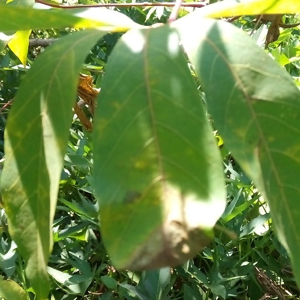

Clase real: cbb


,0
cbb,0.5181
cbsd,0.4177
cmd,0.0490
healthy,0.0113
cgm,0.0039


In [13]:
from PIL import Image
POSICION = 0
fila = partes['test'].iloc[POSICION]
ruta = f"{RAIZ}/{fila['ruta']}"
display(Image.open(ruta).resize((300, 300)))
print('Clase real:', fila['clase'])
analisis.inferencia_una_imagen('E1', ruta)

### C. Recalcular macro-F1 a mano
Macro-F1 = promedio simple del F1 de cada clase. Cada F1 sale de la matriz de confusión:
precisión = aciertos de la clase / todo lo que el modelo llamó así; recall = aciertos / todo lo que realmente era de esa clase.

In [14]:
import numpy as np
from src.evaluar import macro_f1_manual
matriz = np.array(m1['matriz_confusion'])   # filas = clase real, columnas = predicha
for i, c in enumerate(clases):
    vp = matriz[i, i]
    precision = vp / max(matriz[:, i].sum(), 1)
    recall = vp / max(matriz[i, :].sum(), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    print(f'{c:8} precisión={precision:.3f} recall={recall:.3f} F1={f1:.3f}')
print('Macro-F1 a mano      :', round(macro_f1_manual(matriz), 4))
print('Macro-F1 de sklearn  :', round(m1['macro_f1'], 4))

cbb      precisión=0.362 recall=0.484 F1=0.414
cbsd     precisión=0.756 recall=0.638 F1=0.692
cgm      precisión=0.621 recall=0.678 F1=0.648
cmd      precisión=0.876 recall=0.865 F1=0.870
healthy  precisión=0.638 recall=0.705 F1=0.670
Macro-F1 a mano      : 0.659
Macro-F1 de sklearn  : 0.659


In [15]:
# También desde el archivo de predicciones, con scikit-learn:
from sklearn.metrics import f1_score
pred = pd.read_csv('resultados/E1/predicciones_test.csv')
f1_score(pred['real'], pred['predicha'], average='macro')

0.6589743123931078

### D. Cambiar una transformación
Misma foto, distinto brillo: ¿cambia la respuesta del modelo? Cambien `FACTOR` (1.0 = original).

In [16]:
import torch
from src import modelos
from src.comun import dispositivo
from src.entrenar import definir_experimento
FACTOR = 0.5
d = definir_experimento('E1', cfg)
modelo = modelos.crear_modelo(d['modelo'], len(clases), preentrenado=False).to(dispositivo())
modelos.cargar_pesos(modelo, 'checkpoints/E1.pt', dispositivo())
modelo.eval()
for factor in (1.0, FACTOR):
    t = transformaciones(224, brillo=None if factor == 1.0 else factor)
    with torch.no_grad():
        p = torch.softmax(modelo(t(Image.open(ruta).convert('RGB')).unsqueeze(0).to(dispositivo())), 1)[0]
    print(f'brillo x{factor}: predice {clases[int(p.argmax())]} con confianza {float(p.max()):.2f}')

brillo x1.0: predice cbb con confianza 0.52
brillo x0.5: predice cbb con confianza 0.45
